In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Mounted at /content/drive


In [2]:
# 1. membaca file CSV dataset baru (Flood Risk Dataset India)
df = pd.read_csv('/content/drive/MyDrive/Tugas_Data_Science_UAS/flood_risk_dataset_india.csv')

# 2. melihat jumlah baris dan kolom
print("Jumlah baris data:", len(df))
print("Jumlah kolom data:", len(df.columns))

# 3. melihat tipe data setiap kolom
print("\nTipe data tiap kolom:")
print(df.dtypes)

# 4. mengecek missing values dan duplikat
print("\nTotal data yang kosong:", df.isnull().sum().sum())
print("Total baris duplikat:", df.duplicated().sum())

# 5. melihat 5 data teratas
display(df.head())

Jumlah baris data: 10000
Jumlah kolom data: 14

Tipe data tiap kolom:
Latitude                  float64
Longitude                 float64
Rainfall (mm)             float64
Temperature (°C)          float64
Humidity (%)              float64
River Discharge (m³/s)    float64
Water Level (m)           float64
Elevation (m)             float64
Land Cover                 object
Soil Type                  object
Population Density        float64
Infrastructure              int64
Historical Floods           int64
Flood Occurred              int64

Total data yang kosong: 0
Total baris duplikat: 0


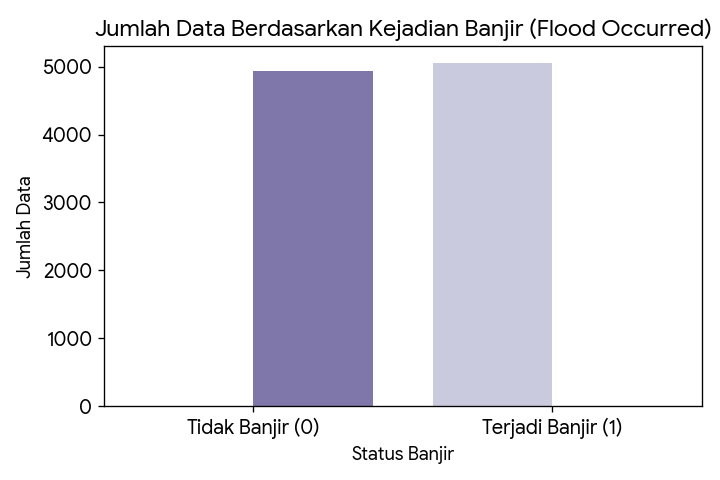

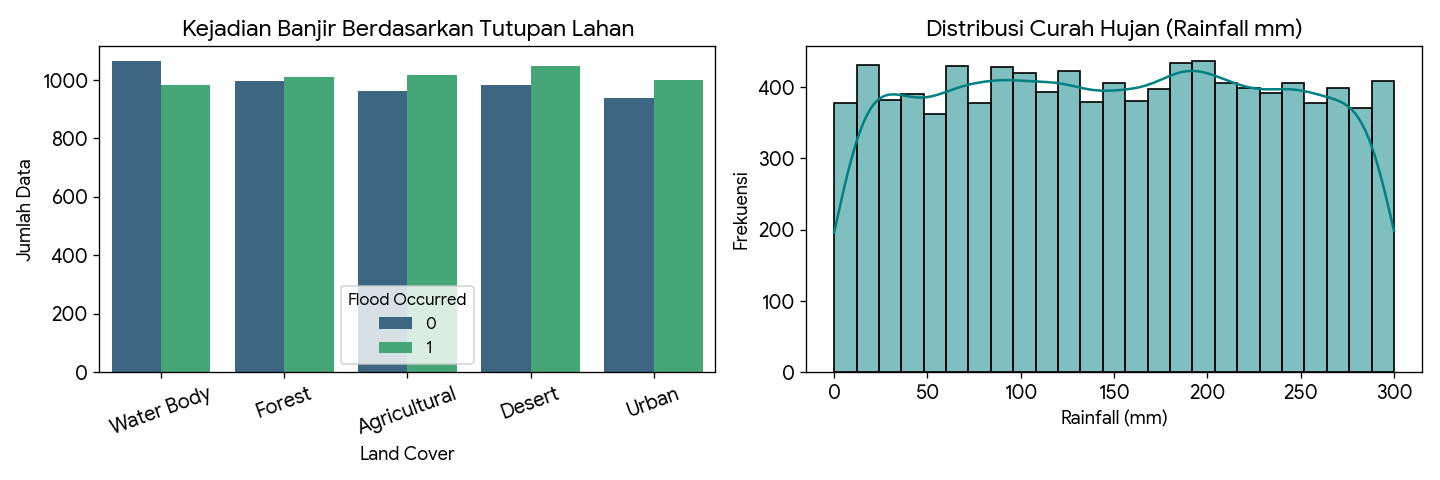

In [3]:
# Visualisasi 1: Distribusi Kejadian Banjir (Target: Flood Occurred)
df['StatusBanjir'] = df['Flood Occurred'].map({0: 'Tidak Banjir (0)', 1: 'Terjadi Banjir (1)'})

plt.figure(figsize=(6, 4))
ax = sns.countplot(
    data=df,
    x='StatusBanjir',
    hue='StatusBanjir',
    order=['Tidak Banjir (0)', 'Terjadi Banjir (1)'],
    palette='Purples'
)
if ax.get_legend() is not None:
    ax.get_legend().remove()
plt.title('Jumlah Data Berdasarkan Kejadian Banjir (Flood Occurred)')
plt.xlabel('Status Banjir')
plt.ylabel('Jumlah Data')
plt.tight_layout()
plt.show()

# Visualisasi 2 & 3: Kejadian Banjir per Tutupan Lahan & Distribusi Curah Hujan
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x='Land Cover', hue='Flood Occurred', palette='viridis', ax=axes[0])
axes[0].set_title('Kejadian Banjir Berdasarkan Tutupan Lahan')
axes[0].set_xlabel('Land Cover')
axes[0].set_ylabel('Jumlah Data')
axes[0].tick_params(axis='x', rotation=20)

sns.histplot(data=df, x='Rainfall (mm)', bins=25, kde=True, color='teal', ax=axes[1])
axes[1].set_title('Distribusi Curah Hujan (Rainfall mm)')
axes[1].set_xlabel('Rainfall (mm)')
axes[1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

# Hapus kolom bantuan visualisasi agar df tetap bersih
df = df.drop(columns=['StatusBanjir'])